<a href="https://colab.research.google.com/github/yasminasouki/DataAnalysis/blob/dev/notebooks/05_unsupervised.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np, pandas as pd, tensorflow as tf, os
print("GPU:", tf.config.list_physical_devices('GPU'))

PROJ = '/content/drive/MyDrive/pneumonia-project'
OUT  = f'{PROJ}/results_05'
os.makedirs(f'{OUT}/figures', exist_ok=True)

split = pd.read_csv(f'{PROJ}/split.csv')
data = np.load(f'{PROJ}/images_224.npz', allow_pickle=True)
images, ids = data['images'], data['patientId']

print("images:", images.shape)
print("Same order as split.csv:", (ids == split['patientId'].values).all())

Mounted at /content/drive
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
images: (8999, 224, 224)
Same order as split.csv: True


In [2]:
from tensorflow.keras.applications.densenet import DenseNet121, preprocess_input

extractor = DenseNet121(include_top=False, weights='imagenet',
                        pooling='avg', input_shape=(224, 224, 3))

def prep(x):
    x = tf.cast(x, tf.float32)[..., None]   # (224,224) -> (224,224,1)
    x = tf.image.grayscale_to_rgb(x)        # -> 3 channels
    return preprocess_input(x)              # ImageNet scaling

ds = tf.data.Dataset.from_tensor_slices(images).map(prep).batch(64).prefetch(tf.data.AUTOTUNE)
features = extractor.predict(ds, verbose=1)

print("Features:", features.shape)
np.savez_compressed(f'{OUT}/features_densenet_imagenet.npz',
                    features=features, patientId=ids)
print("Saved to Drive")

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
141/141 ━━━━━━━━━━━━━━━━━━━━ 138s 550ms/step
Features: (8999, 1024)
Saved to Drive


50% of the variance -> 20 components
80% of the variance -> 139 components
90% of the variance -> 306 components
50 components -> 65.8%


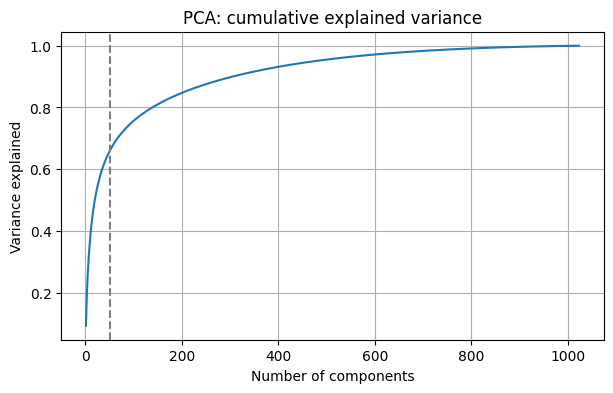

In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

X = StandardScaler().fit_transform(features)   # each feature: mean 0, std 1

pca_full = PCA(random_state=42).fit(X)
cum = pd.Series(pca_full.explained_variance_ratio_.cumsum(),
                index=range(1, len(pca_full.explained_variance_ratio_) + 1))

for t in [0.5, 0.8, 0.9]:
    print(f"{t:.0%} of the variance -> {(cum < t).sum() + 1} components")
print(f"50 components -> {cum[50]:.1%}")

cum.plot(figsize=(7, 4), grid=True, title='PCA: cumulative explained variance',
         xlabel='Number of components', ylabel='Variance explained')
plt.axvline(50, color='gray', linestyle='--')
plt.savefig(f'{OUT}/figures/05_pca_variance.png', dpi=300, bbox_inches='tight')
plt.show()

50 components keep 65.8% of the variance


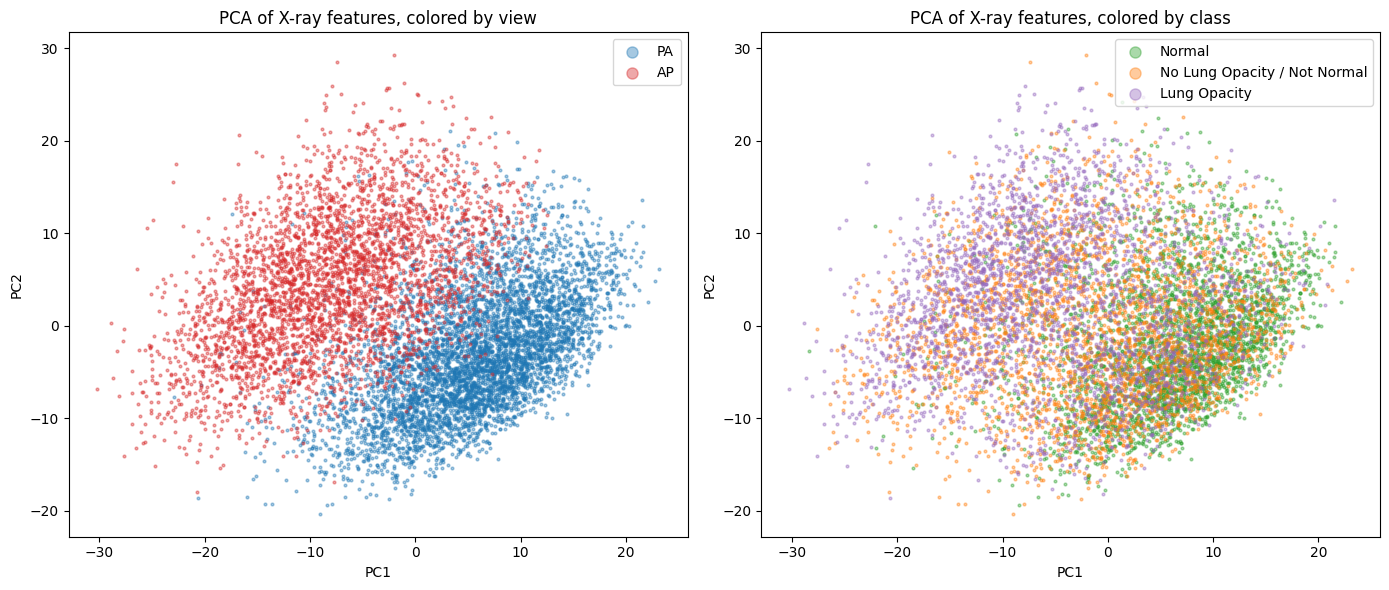


Average PC1 and PC2 by view:
       PC1   PC2
view            
AP   -8.02  4.40
PA    5.45 -2.99

Average PC1 and PC2 by class:
                               PC1   PC2
class                                   
Lung Opacity                 -5.21  2.53
No Lung Opacity / Not Normal -1.10 -0.65
Normal                        5.77 -1.62


In [4]:
N_PC = 50
pca = PCA(n_components=N_PC, random_state=42)
Z = pca.fit_transform(X)
print(f"{N_PC} components keep {pca.explained_variance_ratio_.sum():.1%} of the variance")

pcs = split[['patientId', 'class', 'view', 'age', 'sex']].copy()
pcs['PC1'], pcs['PC2'] = Z[:, 0], Z[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for v, color in [('PA', 'tab:blue'), ('AP', 'tab:red')]:
    pcs[pcs['view'] == v].plot.scatter(x='PC1', y='PC2', s=4, alpha=0.4,
                                       color=color, label=v, ax=axes[0])
axes[0].set_title('PCA of X-ray features, colored by view')

for c, color in [('Normal', 'tab:green'),
                 ('No Lung Opacity / Not Normal', 'tab:orange'),
                 ('Lung Opacity', 'tab:purple')]:
    pcs[pcs['class'] == c].plot.scatter(x='PC1', y='PC2', s=4, alpha=0.4,
                                        color=color, label=c, ax=axes[1])
axes[1].set_title('PCA of X-ray features, colored by class')

for ax in axes:
    ax.legend(markerscale=4)
plt.tight_layout()
plt.savefig(f'{OUT}/figures/05_pca_view_class.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nAverage PC1 and PC2 by view:")
print(pcs.groupby('view')[['PC1', 'PC2']].mean().round(2))
print("\nAverage PC1 and PC2 by class:")
print(pcs.groupby('class')[['PC1', 'PC2']].mean().round(2))

k=2: silhouette = 0.107
k=3: silhouette = 0.069
k=4: silhouette = 0.065
k=5: silhouette = 0.063
k=6: silhouette = 0.065
k=7: silhouette = 0.064
k=8: silhouette = 0.062
k=9: silhouette = 0.061
k=10: silhouette = 0.059


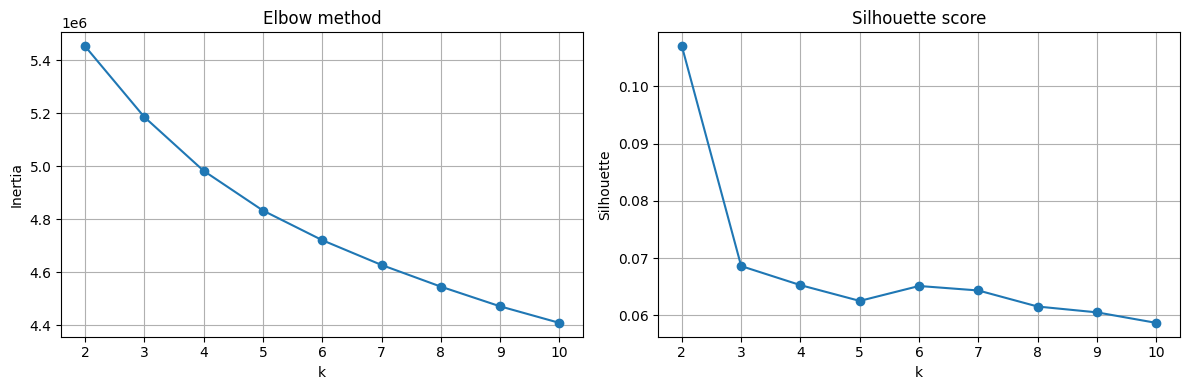

In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

scores = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    sil = silhouette_score(Z, km.labels_, sample_size=4000, random_state=42)
    scores.append({'k': k, 'inertia': km.inertia_, 'silhouette': sil})
    print(f"k={k}: silhouette = {sil:.3f}")

scores = pd.DataFrame(scores).set_index('k')
scores.to_csv(f'{OUT}/kmeans_k_selection.csv')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
scores['inertia'].plot(ax=axes[0], marker='o', grid=True,
                       title='Elbow method', ylabel='Inertia')
scores['silhouette'].plot(ax=axes[1], marker='o', grid=True,
                          title='Silhouette score', ylabel='Silhouette')
plt.tight_layout()
plt.savefig(f'{OUT}/figures/05_choose_k.png', dpi=300, bbox_inches='tight')
plt.show()

Saved clusters.csv: (8999, 12)

Cluster sizes (k=2):
 cluster_k2
0    5526
1    3473
Name: count, dtype: int64

Cluster sizes (k=3):
 cluster_k3
0    2973
1    3009
2    3017
Name: count, dtype: int64


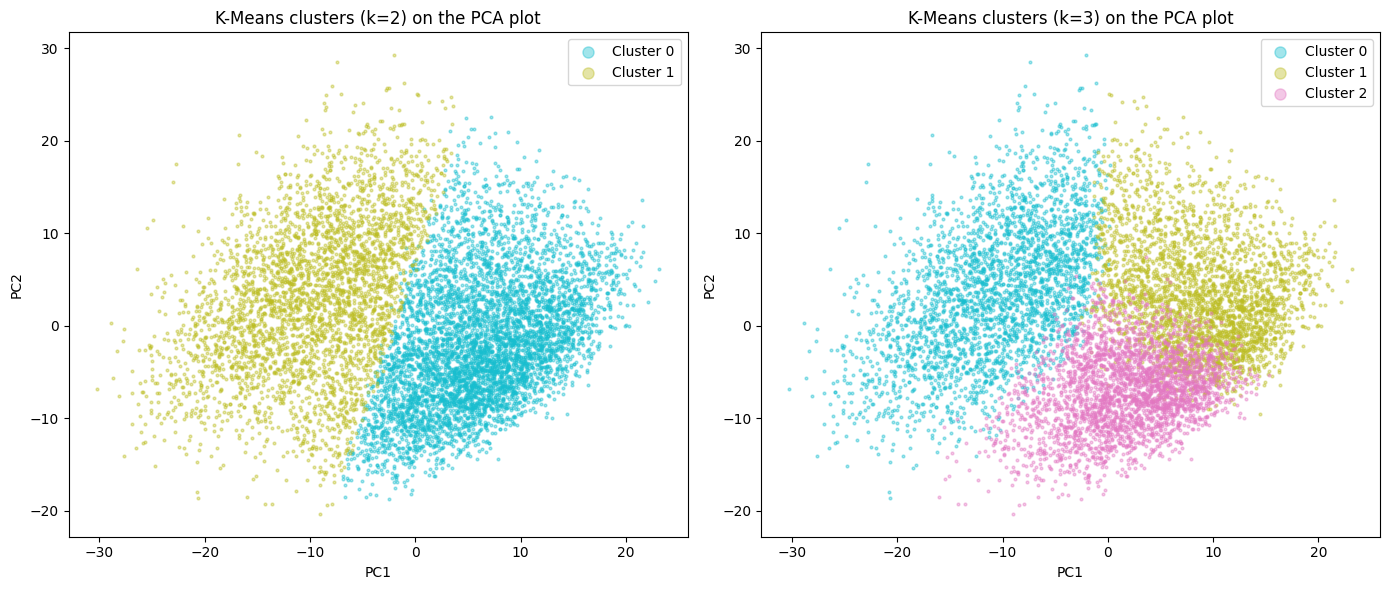

In [6]:
km2 = KMeans(n_clusters=2, n_init=10, random_state=42).fit(Z)
km3 = KMeans(n_clusters=3, n_init=10, random_state=42).fit(Z)

clusters = split[['patientId', 'real_patient_id', 'split', 'class',
                  'view', 'age', 'sex']].copy()
clusters['target'] = (clusters['class'] == 'Lung Opacity').astype(int)
clusters['PC1'], clusters['PC2'] = Z[:, 0], Z[:, 1]
clusters['cluster_k2'] = km2.labels_
clusters['cluster_k3'] = km3.labels_

clusters.to_csv(f'{OUT}/clusters.csv', index=False)
print("Saved clusters.csv:", clusters.shape)
print("\nCluster sizes (k=2):\n", clusters['cluster_k2'].value_counts().sort_index())
print("\nCluster sizes (k=3):\n", clusters['cluster_k3'].value_counts().sort_index())

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
colors = ['tab:cyan', 'tab:olive', 'tab:pink']
for ax, col, k in [(axes[0], 'cluster_k2', 2), (axes[1], 'cluster_k3', 3)]:
    for c in range(k):
        clusters[clusters[col] == c].plot.scatter(x='PC1', y='PC2', s=4, alpha=0.4,
                                                  color=colors[c], label=f'Cluster {c}', ax=ax)
    ax.set_title(f'K-Means clusters (k={k}) on the PCA plot')
    ax.legend(markerscale=4)
plt.tight_layout()
plt.savefig(f'{OUT}/figures/05_kmeans_clusters.png', dpi=300, bbox_inches='tight')
plt.show()